In [51]:
# Initialisation
#  echo: false
# Recharge automatiquement les modules modifiés (évite de redémarrer le kernel)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sci
from scipy.signal import hilbert
from scipy.stats import kurtosis
from scipy.fftpack import fft, fftfreq
from IPython.display import Markdown

# Cherche le dossier racine du projet (BDS_Fault_Detection) pour faire les imports depuis Sources/
dossier = Path().resolve()
for parent in (dossier, *dossier.parents):
    if "BDS_Fault_Detection" in parent.name:
        RACINE = parent
sys.path.insert(0, str(RACINE))

# Importation des fonctions du projet (dossier Sources/). Attention de l'ordre d'importation  !
from Sources import data, config, signaux, indicateurs, features, models


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [52]:
# Sélection du scope de données à traiter (sources, défauts, diamètres, positions, charges, canaux)
selection = data.selectionner(
    sources=("12kDE", "Normal"),
    defauts=("IR", "B", "OR"),
    diametres=(7, 14, 21), positions_or=("6",),
    charges=(0, 1, 2, 3),
    canaux={"12kDE": ("DE",), 
            "Normal": ("DE")},
)

In [64]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from Sources.data import selectionner, charger
from Sources.config import DUREE_FENETRE

def construire_fenetres_brutes(selection, canal="DE", duree=DUREE_FENETRE, recouvrement=0.5):
    """Renvoie (SB, infos) : signaux BRUTS (pas encore normalisés) + infos par fenetre."""
    SB, lignes = [], []
    for nom, info in selection.iterrows():
        s = charger(nom)
        for i, val in enumerate(features.fenetrer(s[canal], s["fs"], duree=duree, recouvrement=recouvrement)):
            SB.append(val)                                   # brut, sans normaliser
            lignes.append({"fichier": nom, "fenetre": i, "canal": canal,
                           "defaut": info["defaut"], "charge_hp": info["charge_hp"],
                           "rpm": s["rpm"], "fs": s["fs"]})
    return np.array(SB, dtype=np.float32), pd.DataFrame(lignes)

SB, infos = construire_fenetres_brutes(selection, canal="DE")

SBNorm = StandardScaler().fit_transform(SB.T).T            # Standardisation

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from Sources.data import selectionner, charger

def construire_fenetres_brutes(selection, canal="DE", taille=1024):
    """Renvoie (SB, infos) : signaux BRUTS (pas encore normalisés) + infos par fenetre."""
    SB, lignes = [], []
    for nom, info in selection.iterrows():
        s = charger(nom)
        for i, val in enumerate(features.fenetrer(s[canal], taille, recouvrement=0.5)):
            SB.append(val)                                   # brut, sans normaliser
            lignes.append({"fichier": nom, "fenetre": i, "canal": canal,
                           "defaut": info["defaut"], "charge_hp": info["charge_hp"],
                           "rpm": s["rpm"], "fs": s["fs"]})
    return np.array(SB, dtype=np.float32), pd.DataFrame(lignes)

SB, infos = construire_fenetres_brutes(selection, canal="DE", taille=1024)

SBNorm = StandardScaler().fit_transform(SB.T).T            # Standardisation

In [ ]:
import numpy as np
import pandas as pd
from Sources.data import selectionner, charger

# Constructions des fenetres de signaux BRUTES : signaux + infos

def fenetre_brute_recouvr(x, taille=1024, recouvrement=0.5):
    """Decoupe chaque signal en fenetres de taille paramétrable avec recouvrement (50 % par defaut)."""
    pas = int(taille * (1 - recouvrement))
    return [x[i:i + taille] for i in range(0, len(x) - taille + 1, pas)]

def construire_fenetres_brutes(selection, canal="DE", taille=1024):
    """Renvoie (SBNorm, infos) :
       SBNorm    : array (n_fenetres, taille), chaque fenetre 
       infos : DataFrame, une ligne par fenetre (pour le split et l'evaluation)
    """
    SBNorm, lignes = [], []
    for nom, info in selection.iterrows():          # Fichiers depuis sélection
        s = charger(nom)                             # signaux brutes
        signBrute = s[canal]
        for i, val in enumerate(fenetre_brute_recouvr(signBrute, taille)):
            SBNorm.append((val - val.mean()) / val.std())           # normalisation par fenetre
            lignes.append({"fichier": nom, "fenetre": i, "canal": canal,
                           "defaut": info["defaut"], "charge_hp": info["charge_hp"],
                           "rpm": s["rpm"], "fs": s["fs"]})
    return np.array(SBNorm, dtype=np.float32), pd.DataFrame(lignes)

# Exemple : plan 12 kHz cote moteur, comme dans votre rapport
SBNorm, infos = construire_fenetres_brutes(selection, canal="DE", taille=1024)

# Preprocessing
1. Fenêtrage par recouvrement
On créer des fenêtres dans le signal pour avoir d'avantage de données d'entrainement (comme précédement).
On veille à avoir des fenêtres assez longue pour ne pas perdre d'informations :
    Une fenêtre de 1024 points à 12 kHz dure environ 85 ms, soit environ 5 périodes de BPFO, donc assez pour capter la fréquence des chocs.

Le recouvrement sert à mieux capter les chocs :
Sans recouvrement, un choc de défaut qui tomberait à cheval sur le partage de deux fenêtres est vue "à moitié" dans chaque fenêtre, le modèle verrait donc moins bien l'événement "choc". Avec du recouvrement, chaque événement apparaît complet dans au moins une fenêtre, on ne perd pas d'information.


2. Normalisation
On normalise le signal brut car l'amplitude peut varier (notamment avec la charge) et on cherche à capter les variations des signaux (les chocs), pas les valeurs abosules du signal.
Si la charge augmente, l'amplitude du signal (de la fenêtre) augmente, et le modèle va détecter une variation et donc un défaut, hors l'augmentation de charge n'est pas un défaut !

In [ ]:
# Split PAR FICHIER + masque "sain" pour l'entrainement
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
i_train, i_test = next(gss.split(infos, groups=infos["fichier"]))

sain = (infos["defaut"] == "Sain").to_numpy()
X_train_sain = SBNorm[i_train][sain[i_train]]         # Le train ne comporte que les données saines !

In [62]:
# ---------------------------------------------------------------
# 3. Conv1D-AE minimal (Keras) + score d'anomalie = MSE
# ---------------------------------------------------------------
import tensorflow as tf
import keras
from keras import layers

def conv1d_ae(taille=SB.shape[1]):
    Input = keras.Input(shape=(taille, 1))
    # Encodeur : 2 poolings
    x = layers.Conv1D(32, 7, activation="relu", padding="same")(Input) 
    x = layers.MaxPooling1D(2, padding="same")(x)                       
    x = layers.Conv1D(16, 5, activation="relu", padding="same")(x)      
    x = layers.MaxPooling1D(2, padding="same")(x)                       
    latent = layers.Conv1D(8, 3, activation="relu", padding="same")(x)
    # Decodeur : miroir exact
    x = layers.Conv1D(16, 5, activation="relu", padding="same")(latent)  
    x = layers.UpSampling1D(2)(x)                                         
    x = layers.Conv1D(32, 7, activation="relu", padding="same")(x)        
    x = layers.UpSampling1D(2)(x)                                       
    sortie = layers.Conv1D(1, 7, padding="same")(x)           
    modele = keras.Model(Input, sortie)
    modele.compile(optimizer="adam", loss="mse")
    return modele


In [63]:
modele = conv1d_ae(taille=1024)
hist = modele.fit(X_train_sain[..., None], X_train_sain[..., None], epochs=20, batch_size=64, validation_split=0.1, verbose=1)

Epoch 1/20


ValueError: Input 0 with name 'input_layer_7' of layer 'functional_7' is incompatible with the layer: expected shape=(None, 1024, 1), found shape=(None, 2400)

In [41]:
# score d'anomalie : erreur de reconstruction par fenetre
def score_anomalie(modele, SBNorm):
    Xr = modele.predict(SBNorm[..., None], verbose=1)[..., 0]
    return ((SBNorm - Xr) ** 2).mean(axis=1)

infos["score"] = score_anomalie(modele, SBNorm)
seuil = np.percentile(infos["score"].to_numpy()[i_train][sain[i_train]], 99)  # percentile 99 des sains du train
infos["alarme"] = infos["score"] > seuil

370/370 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step


In [42]:
# ---------------------------------------------------------------
# 4. Evaluation simple sur le test : sain vs defaut
# ---------------------------------------------------------------
from sklearn.metrics import roc_auc_score

y_test = (infos["defaut"].to_numpy()[i_test] != "Sain")     # 0 = sain, 1 = defaut
auc = roc_auc_score(y_test, infos["score"].to_numpy()[i_test])
print(f"ROC-AUC detection sain/defaut : {auc:.3f}")

ROC-AUC detection sain/defaut : 1.000


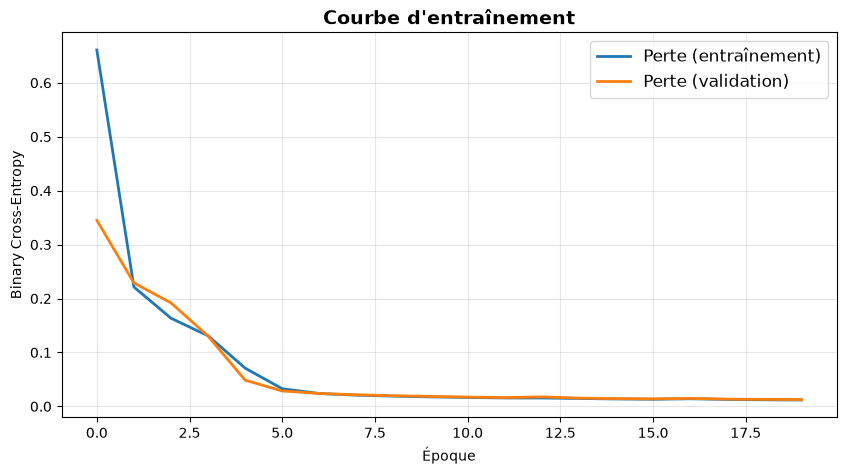

In [43]:
plt.figure(figsize=(10, 5))
plt.plot(hist.history["loss"], label="Perte (entraînement)", linewidth=2)
plt.plot(hist.history["val_loss"], label="Perte (validation)", linewidth=2)
plt.xlabel("Époque")
plt.ylabel("Binary Cross-Entropy")
plt.title("Courbe d'entraînement", fontsize=14, fontweight="bold")
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

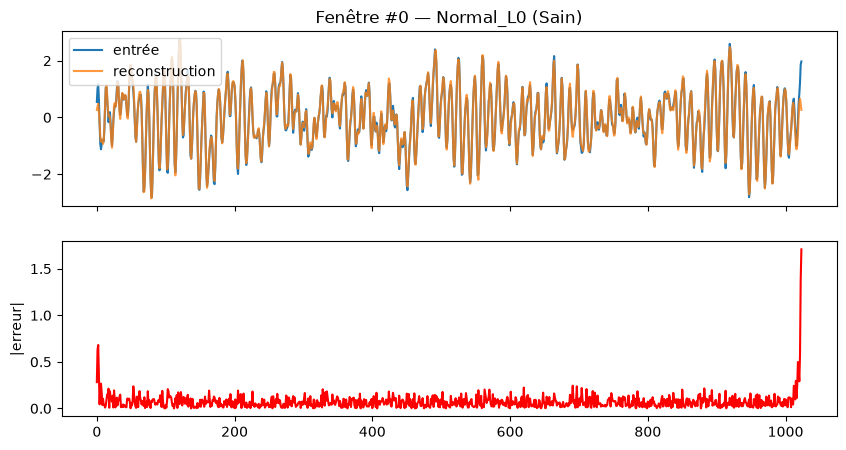

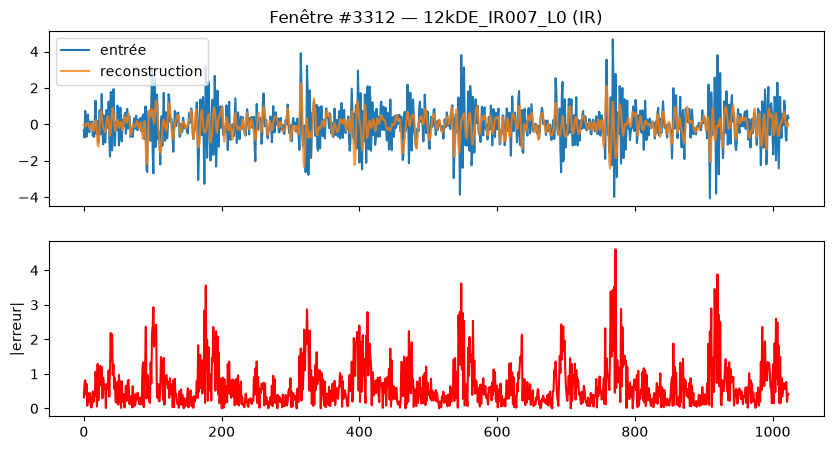

In [44]:
def montrer_reconstruction(i):
    x = SBNorm[i]
    xr = modele.predict(x[None, :, None], verbose=0)[0, :, 0]
    fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    ax[0].plot(x, label="entrée"); ax[0].plot(xr, label="reconstruction", alpha=0.8)
    ax[0].legend(); ax[0].set_title(f"Fenêtre #{i} — {infos.loc[i, 'fichier']} ({infos.loc[i, 'defaut']})")
    ax[1].plot(np.abs(x - xr), color="red"); ax[1].set_ylabel("|erreur|")
    plt.show()

montrer_reconstruction(i_train[sain[i_train]][0])   # fenêtre SAINE  → bien reconstruite
montrer_reconstruction(i_test[~sain[i_test]][0])    # fenêtre DÉFAUT → mal reconstruite (pics rouges aux chocs)